## orders

In [2]:
import pandas as pd

df_orders=pd.read_csv("orders.csv")

print(df_orders.head())
print(df_orders.shape)
df_orders.info()

                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status order_purchase_timestamp order_approved_at  \
0    delivered          10/2/2017 10:56   10/2/2017 11:07   
1    delivered          7/24/2018 20:41    7/26/2018 3:24   
2    delivered            8/8/2018 8:38     8/8/2018 8:55   
3    delivered         11/18/2017 19:28  11/18/2017 19:45   
4    delivered          2/13/2018 21:18   2/13/2018 22:20   

  order_delivered_carrier_date order_delivered_customer_date  \
0              10/4/2017 19:55              10/10/2017 21:25   
1              7/26/2018 14:31                8/7/2018 15:27   
2 

In [3]:
# القيم الفاضية في كل عمود
# الفراغات في أعمدة التسليم طبيعية لانها بتمثل الطلبات اللي اتلغت أو لسه ما اتسلمتش
print(df_orders.isnull().sum())

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [4]:
# حساب القيم لمتكرره في كل عمود
# order_id لازم يكون unique، ومفيش صفوف مكررة بالكامل
for col in df_orders:
    
    print(f'duplicates in {col}:',df_orders[col].duplicated().sum())

duplicates in order_id: 0
duplicates in customer_id: 0
duplicates in order_status: 99433
duplicates in order_purchase_timestamp: 10652
duplicates in order_approved_at: 48978
duplicates in order_delivered_carrier_date: 37896
duplicates in order_delivered_customer_date: 23791
duplicates in order_estimated_delivery_date: 98982


In [5]:
#تحديد انواع بيانات الاعمدة واكتشاف type errors
print(df_orders.dtypes)

order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object


In [6]:
# توزيع حالات الطلبات (order_status)

print(df_orders["order_status"].value_counts(dropna=False))


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [7]:
# تحويل أعمدة التواريخ لنوع datetime عشان نقدر نحسب عليها

date_columns=[
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"

]

for col in date_columns:
    df_orders[col]=pd.to_datetime(df_orders[col],errors="coerce")
 
print("Rows:", len(df_orders))
print("Columns:", len(df_orders.columns))   
print(df_orders[date_columns].dtypes)

Rows: 99441
Columns: 8
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object


In [8]:
# عدد الطلبات شهريًا (كل الحالات، بدون استبعاد الملغي)
# ملاحظة: أول وآخر شهور في الداتا ناقصة، فمتتحسبش في الاتجاه
df_orders["order_month"] = df_orders["order_purchase_timestamp"].dt.to_period("M")

orders_by_month = df_orders.groupby("order_month").size() 

print(orders_by_month)

order_month
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, dtype: int64


In [9]:
# فرق الأيام بين التسليم الفعلي والمتوقع (موجب = متأخر، سالب = قبل الميعاد)
df_orders["late_deliveries"] = (
    df_orders["order_delivered_customer_date"] - df_orders["order_estimated_delivery_date"]
).dt.total_seconds() / (60 * 60 * 24)

# أعلى 10 طلبات متأخرة
top_10_delays = df_orders.nlargest(10, "late_deliveries")

cols_to_show = [
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
    "late_deliveries",
    "order_status",
]

print(top_10_delays[cols_to_show].round({"late_deliveries": 2}))

      order_delivered_customer_date order_estimated_delivery_date  \
55619           2018-09-19 23:24:00                    2018-03-15   
19590           2017-09-19 14:36:00                    2017-03-22   
11399           2018-07-13 20:51:00                    2018-01-19   
81401           2017-09-19 17:00:00                    2017-04-05   
89130           2017-09-19 14:00:00                    2017-04-06   
61610           2017-09-19 15:12:00                    2017-04-07   
68769           2017-09-19 17:14:00                    2017-04-10   
40847           2017-12-04 18:36:00                    2017-06-26   
38509           2017-09-19 14:38:00                    2017-04-11   
54480           2017-09-19 14:38:00                    2017-04-13   

       late_deliveries order_status  
55619           188.98    delivered  
19590           181.61    delivered  
11399           175.87    delivered  
81401           167.71    delivered  
89130           166.58    delivered  
61610       

In [10]:
# نسبة التأخير: الطلبات المسلّمة فقط، وليها تاريخ تسليم فعلي ومتوقع
delivered = df_orders[ ( df_orders["order_status"]=="delivered")
                       & (df_orders["order_delivered_customer_date"].notna())
                       &(df_orders["order_estimated_delivery_date"].notna())].copy()  # copy عشان التعديلات ما تأثرش على df_orders
delivered["late_orders"] = (
    delivered["order_delivered_customer_date"]>
    delivered["order_estimated_delivery_date"]
)
print(delivered["late_orders"].value_counts())
delay_rate= delivered["late_orders"].mean()*100
print(f"delay_rate:{delay_rate:.2f}%")

late_orders
False    88644
True      7826
Name: count, dtype: int64
delay_rate:8.11%


In [11]:
# مدة التوصيل بالأيام: من تاريخ الشراء لتاريخ التسليم الفعلي

df_orders["delivery_days"] = (
    df_orders["order_delivered_customer_date"]
    - df_orders["order_purchase_timestamp"]
).dt.total_seconds() / (60 * 60 * 24)

print(df_orders["delivery_days"].describe())

count    96476.000000
mean        12.558659
std          9.546533
min          0.533333
25%          6.766493
50%         10.218056
75%         15.720139
max        209.628472
Name: delivery_days, dtype: float64


## order items

In [12]:
df_order_item=pd.read_csv("order_items.csv")

print(df_order_item.head())
print(df_order_item.shape)
df_order_item.info()

                           order_id  order_item_id  \
0  00010242fe8c5a6d1ba2dd792cb16214              1   
1  00018f77f2f0320c557190d7a144bdd3              1   
2  000229ec398224ef6ca0657da4fc703e              1   
3  00024acbcdf0a6daa1e931b038114c75              1   
4  00042b26cf59d7ce69dfabb4e55b4fd9              1   

                         product_id                         seller_id  \
0  4244733e06e7ecb4970a6e2683c13e61  48436dade18ac8b2bce089ec2a041202   
1  e5f2d52b802189ee658865ca93d83a8f  dd7ddc04e1b6c2c614352b383efe2d36   
2  c777355d18b72b67abbeef9df44fd0fd  5b51032eddd242adc84c38acab88f23d   
3  7634da152a4610f1595efa32f14722fc  9d7a1d34a5052409006425275ba1c2b4   
4  ac6c3623068f30de03045865e4e10089  df560393f3a51e74553ab94004ba5c87   

   shipping_limit_date   price  freight_value  
0  2017-09-19 09:45:35   58.90          13.29  
1  2017-05-03 11:05:13  239.90          19.93  
2  2018-01-18 14:48:30  199.00          17.87  
3  2018-08-15 10:10:18   12.99          12.7

In [13]:
# القيم الفاضية في order_items
print(df_order_item.isnull().sum())

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64


In [14]:
# المفتاح الطبيعي للجدول (order_id, order_item_id) لازم يكون unique
print("duplicated (order_id, order_item_id):", df_order_item.duplicated(subset=["order_id", "order_item_id"]).sum())
print("fully duplicated rows:", df_order_item.duplicated().sum())

# عدد القيم الفريدة
print("unique orders  :", df_order_item["order_id"].nunique())
print("unique products:", df_order_item["product_id"].nunique())
print("unique sellers :", df_order_item["seller_id"].nunique())

duplicated (order_id, order_item_id): 0
fully duplicated rows: 0
unique orders  : 98666
unique products: 32951
unique sellers : 3095


In [15]:
# عدد البنود (items) في كل طلب
items_per_order = df_order_item["order_id"].value_counts()
print(items_per_order.describe())
print(items_per_order.value_counts().sort_index().head(10))

count    98666.000000
mean         1.141731
std          0.538452
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         21.000000
Name: count, dtype: float64
count
1     88863
2      7516
3      1322
4       505
5       204
6       198
7        22
8         8
9         3
10        8
Name: count, dtype: int64


In [16]:
# أنواع الأعمدة
print(df_order_item.dtypes)

order_id                   str
order_item_id            int64
product_id                 str
seller_id                  str
shipping_limit_date        str
price                  float64
freight_value          float64
dtype: object


In [17]:
# تحويل shipping_limit_date من نص لـ datetime
df_order_item["shipping_limit_date"] = pd.to_datetime(df_order_item["shipping_limit_date"], errors="coerce")

print(df_order_item["shipping_limit_date"].dtype)
print("NaT after conversion:", df_order_item["shipping_limit_date"].isna().sum())

datetime64[us]
NaT after conversion: 0


In [18]:
# إحصائيات السعر وتكلفة الشحن للبند الواحد
print("price:")
print(df_order_item["price"].describe())

print("\nfreight_value:")
print(df_order_item["freight_value"].describe())

price:
count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
max        6735.000000
Name: price, dtype: float64

freight_value:
count    112650.000000
mean         19.990320
std          15.806405
min           0.000000
25%          13.080000
50%          16.260000
75%          21.150000
max         409.680000
Name: freight_value, dtype: float64


In [19]:
# 1. عدد الـ order_id الفريدة في جدول orders
unique_orders_in_orders = df_orders["order_id"].nunique()
print(f"Unique order_ids in orders table: {unique_orders_in_orders}")

# 2. عدد الـ order_id الفريدة في جدول order_items
unique_orders_in_items = df_order_item["order_id"].nunique()
print(f"Unique order_ids in order_items table: {unique_orders_in_items}")

# 3. إجمالي عدد الصفوف في جدول order_items (أكتر من الطلبات لأن الطلب فيه أكتر من بند)
print(f"Total rows in order_items table: {len(df_order_item)}")

# 4. الطلبات اللي ملهاش بنود
print(f"Orders without items: {unique_orders_in_orders - unique_orders_in_items}")

Unique order_ids in orders table: 99441
Unique order_ids in order_items table: 98666
Total rows in order_items table: 112650
Orders without items: 775


In [20]:
# الطلبات اللي ملهاش items  وايه حالتها
df_total = df_orders.merge(df_order_item, on= 'order_id',how='left' ,indicator=True)
df_filter = df_total[df_total['_merge'] == 'left_only']
print(df_filter["order_status"].value_counts())

order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1
Name: count, dtype: int64


# Decision: Sales = SUM(price) from order_items. freight_value is excluded (shipping cost, not product revenue).

In [21]:
# Decision: count all orders except canceled & unavailable (never fulfilled).
# Delivered-only is reserved for delivery/late analysis.
orders_valid = df_orders[~df_orders["order_status"].isin(["canceled", "unavailable"])].copy()
print("all orders:", len(df_orders), "| valid orders:", len(orders_valid))

all orders: 99441 | valid orders: 98207


valid orders: 98207 | items after merge: 112101
                revenue  orders  items     aov
order_month                                   
2017-01       120098.27     787    953  152.60
2017-02       244959.35    1718   1936  142.58
2017-03       368341.32    2617   2975  140.75
2017-04       353842.98    2377   2660  148.86
2017-05       503159.19    3640   4106  138.23
2017-06       429916.61    3205   3571  134.14
2017-07       492287.30    3946   4493  124.76
2017-08       568245.79    4272   4882  133.02
2017-09       621415.91    4227   4815  147.01
2017-10       660179.62    4547   5300  145.19
2017-11      1003862.14    7421   8626  135.27
2017-12       742183.79    5618   6300  132.11
2018-01       945456.29    7187   8173  131.55
2018-02       837895.43    6624   7597  126.49
2018-03       981051.06    7168   8195  136.87
2018-04       993592.98    6919   7957  143.60
2018-05       992871.75    6833   7898  145.31
2018-06       863265.53    6145   7060  140.48
2018-07     

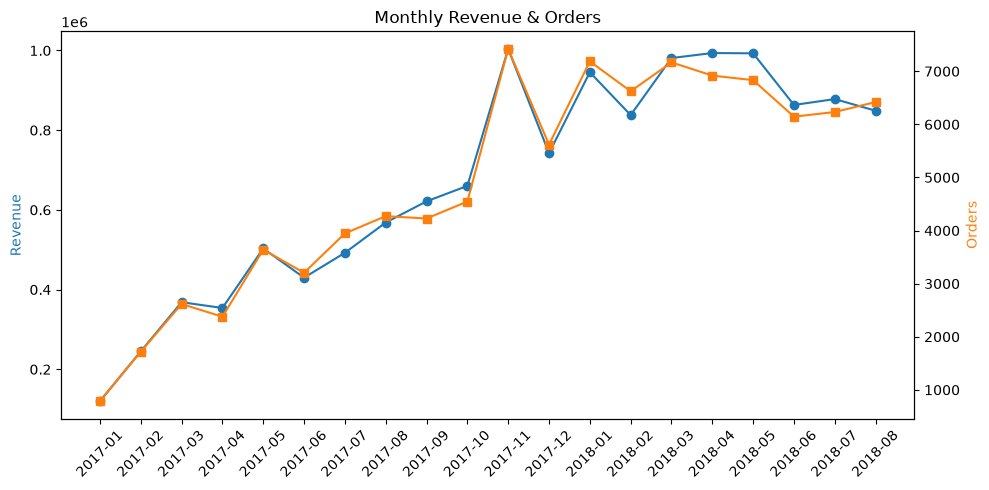

In [22]:
import matplotlib.pyplot as plt

# الطلبات الصالحة (orders_valid من خلية 23) مدموجة مع بنودها
len_before = len(orders_valid)
grand_df = orders_valid.merge(
    df_order_item, on="order_id", how="inner", validate="one_to_many"
)
print("valid orders:", len_before, "| items after merge:", len(grand_df))

# نافذة التحليل: يناير 2017 – أغسطس 2018 (الأشهر الناقصة في الأطراف مستبعدة)
grand_df["order_month"] = grand_df["order_purchase_timestamp"].dt.to_period("M")
grand_df = grand_df[
    (grand_df["order_month"] >= "2017-01") & (grand_df["order_month"] <= "2018-08")
]

monthly = grand_df.groupby("order_month").agg(
    revenue=("price", "sum"),          # الإيراد = sum للسعر
    orders=("order_id", "nunique"),    # الطلبات = nunique مش size
    items=("order_item_id", "count"),  # عدد البنود
)
monthly["aov"] = (monthly["revenue"] / monthly["orders"]).round(2)
print(monthly)

fig, ax1 = plt.subplots(figsize=(10, 5))
x = monthly.index.astype(str)
ax1.plot(x, monthly["revenue"], marker="o", color="tab:blue")
ax1.set_ylabel("Revenue", color="tab:blue")
ax1.tick_params(axis="x", rotation=45)
ax2 = ax1.twinx()
ax2.plot(x, monthly["orders"], marker="s", color="tab:orange")
ax2.set_ylabel("Orders", color="tab:orange")
plt.title("Monthly Revenue & Orders")
plt.tight_layout()
plt.show()

### الاتجاه الشهري للمبيعات (يناير 2017 – أغسطس 2018)

نما الإيراد الشهري بشكل واضح خلال 2017، من **120,098.27** في يناير إلى ذروته في نوفمبر بقيمة **1,003,862.14**، ثم تراجع في ديسمبر إلى **742,183.79**. قد تعود ذروة نوفمبر إلى حملات الخصومات الموسمية مثل Black Friday، وهذه فرضية تحتاج إلى تحقق ولا تثبتها البيانات وحدها.

في 2018 استقر الإيراد نسبيًا، وتراوح بين **837,895.43** و**993,592.98** شهريًا. وبما أن متوسط قيمة الطلب (AOV) ظل متقاربًا، إذ تراوح بين **126.49** و**145.31**، فإن التغير في الإيراد يعود أساسًا إلى **زيادة عدد الطلبات** وليس إلى ارتفاع قيمة الطلب الواحد.

وبمقارنة نفس الأشهر (يناير–أغسطس)، ارتفع الإيراد بنحو **138%** بين 2017 و2018، بينما ارتفع عدد الطلبات بنحو **137%** وبقي الـ AOV شبه ثابت (**136.55** مقابل **137.14**).

## products

In [23]:
# جدول products + جدول ترجمة أسماء الفئات
df_product = pd.read_csv("products.csv")
df_pcn = pd.read_csv("product_category_name_translation.csv")

print(df_product.head())
print(df_product.shape)
df_product.info()
print("translation table:", df_pcn.shape)

                         product_id  product_category_name  \
0  1e9e8ef04dbcff4541ed26657ea517e5             perfumaria   
1  3aa071139cb16b67ca9e5dea641aaa2f                  artes   
2  96bd76ec8810374ed1b65e291975717f          esporte_lazer   
3  cef67bcfe19066a932b7673e239eb23d                  bebes   
4  9dc1a7de274444849c219cff195d0b71  utilidades_domesticas   

   product_name_lenght  product_description_lenght  product_photos_qty  \
0                 40.0                       287.0                 1.0   
1                 44.0                       276.0                 1.0   
2                 46.0                       250.0                 1.0   
3                 27.0                       261.0                 1.0   
4                 37.0                       402.0                 4.0   

   product_weight_g  product_length_cm  product_height_cm  product_width_cm  
0             225.0               16.0               10.0              14.0  
1            1000.0       

In [24]:
# بنود الطلبات الصالحة فقط (نفس قرار استبعاد canceled & unavailable)
items_valid = df_order_item[df_order_item["order_id"].isin(orders_valid["order_id"])]
len_before = len(items_valid)

items_prod = items_valid.merge(
    df_product, on="product_id", how="left", validate="many_to_one"
)
items_cat = items_prod.merge(
    df_pcn, on="product_category_name", how="left", validate="many_to_one"
)

print(f"before: {len_before} | after: {len(items_cat)}")

before: 112101 | after: 112101


In [25]:
# منتجات من غير فئة (product_category_name)
missing_cat = df_product["product_category_name"].isna()
print(missing_cat.value_counts())
print(f"Products without category: {missing_cat.mean():.2%}")

product_category_name
False    32341
True       610
Name: count, dtype: int64
Products without category: 1.85%


In [26]:
# 1. البنود اللي منتجها من غير فئة -> "unknown"
print("items with null category:", items_cat["product_category_name"].isna().sum())
items_cat["product_category_name"] = items_cat["product_category_name"].fillna("unknown")

# 2. فئات ملهاش ترجمة إنجليزي: نستخدم الاسم البرتغالي بدل ما تتشال من التحليل
missing_en = items_cat["product_category_name_english"].isna()
print("items with no English name:", missing_en.sum())
print(items_cat.loc[missing_en, "product_category_name"].value_counts())

items_cat["product_category_name_english"] = items_cat["product_category_name_english"].fillna(
    items_cat["product_category_name"]
)
print("remaining nulls:", items_cat["product_category_name_english"].isna().sum())

items with null category: 1589
items with no English name: 1611
product_category_name
unknown                                          1589
portateis_cozinha_e_preparadores_de_alimentos      14
pc_gamer                                            8
Name: count, dtype: int64
remaining nulls: 0


In [27]:
# تحليل الفئات: الإيراد، عدد الطلبات، متوسط سعر البند
category_analysis = (
    items_cat
    .groupby("product_category_name_english")
    .agg(
        revenue=("price", "sum"),
        orders=("order_id", "nunique"),
        avg_price=("price", "mean")
    )
    .reset_index()
)
print("categories:", len(category_analysis))

categories: 74


In [28]:
# أعلى 10 فئات من حيث الإيراد
top_10_revenue = category_analysis.sort_values("revenue", ascending=False).head(10)
print(top_10_revenue.round(2))

   product_category_name_english     revenue  orders  avg_price
43                 health_beauty  1255695.13    8800     130.34
73                 watches_gifts  1198185.21    5604     200.70
7                 bed_bath_table  1035964.06    9399      93.36
67                sports_leisure   979740.92    7673     114.06
15         computers_accessories   904322.02    6654     116.22
39               furniture_decor   727465.05    6425      87.67
49                    housewares   626825.80    5847      90.65
20                    cool_stuff   620770.49    3616     164.27
5                           auto   586585.73    3872     139.53
42                  garden_tools   481009.94    3505     111.14


In [29]:
# أعلى 10 فئات من حيث عدد الطلبات
top_10_orders = category_analysis.sort_values("orders", ascending=False).head(10)
print(top_10_orders.round(2))

   product_category_name_english     revenue  orders  avg_price
7                 bed_bath_table  1035964.06    9399      93.36
43                 health_beauty  1255695.13    8800     130.34
67                sports_leisure   979740.92    7673     114.06
15         computers_accessories   904322.02    6654     116.22
39               furniture_decor   727465.05    6425      87.67
49                    housewares   626825.80    5847      90.65
73                 watches_gifts  1198185.21    5604     200.70
70                     telephony   322342.64    4183      71.20
5                           auto   586585.73    3872     139.53
71                          toys   479808.54    3855     117.51


In [30]:
# أعلى 10 فئات في متوسط سعر البند (فئات فيها 500 طلب على الأقل عشان المتوسط يكون موثوق)
top_10_avg_price = (
    category_analysis[category_analysis["orders"] >= 500]
    .sort_values("avg_price", ascending=False)
    .head(10)
)
print(top_10_avg_price.round(2))

      product_category_name_english     revenue  orders  avg_price
56              musical_instruments   187788.44     620     280.70
65                 small_appliances   187907.26     622     280.04
73                    watches_gifts  1198185.21    5604     200.70
20                       cool_stuff   620770.49    3616     164.27
57                 office_furniture   273580.70    1272     161.88
17  construction_tools_construction   144550.19     746     155.93
5                              auto   586585.73    3872     139.53
16                   consoles_games   154927.27    1054     137.47
6                              baby   410312.20    2868     134.84
43                    health_beauty  1255695.13    8800     130.34


In [31]:
# مساهمة كل فئة في الإيراد (Pareto)
category_analysis = category_analysis.sort_values("revenue", ascending=False).copy()

total_revenue = category_analysis["revenue"].sum()
category_analysis["revenue_share"] = category_analysis["revenue"] / total_revenue * 100
category_analysis["cumulative_share"] = category_analysis["revenue_share"].cumsum()

print(category_analysis.head(10).round(2))

# أرقام الاستنتاج
top5_share = category_analysis["revenue_share"].head(5).sum()
n_80 = (category_analysis["cumulative_share"] < 80).sum() + 1
print(f"\nTop 5 share: {top5_share:.1f}%")
print(f"Categories needed for 80%: {n_80} of {len(category_analysis)}")

   product_category_name_english     revenue  orders  avg_price  \
43                 health_beauty  1255695.13    8800     130.34   
73                 watches_gifts  1198185.21    5604     200.70   
7                 bed_bath_table  1035964.06    9399      93.36   
67                sports_leisure   979740.92    7673     114.06   
15         computers_accessories   904322.02    6654     116.22   
39               furniture_decor   727465.05    6425      87.67   
49                    housewares   626825.80    5847      90.65   
20                    cool_stuff   620770.49    3616     164.27   
5                           auto   586585.73    3872     139.53   
42                  garden_tools   481009.94    3505     111.14   

    revenue_share  cumulative_share  
43           9.31              9.31  
73           8.88             18.18  
7            7.68             25.86  
67           7.26             33.12  
15           6.70             39.82  
39           5.39             45.2

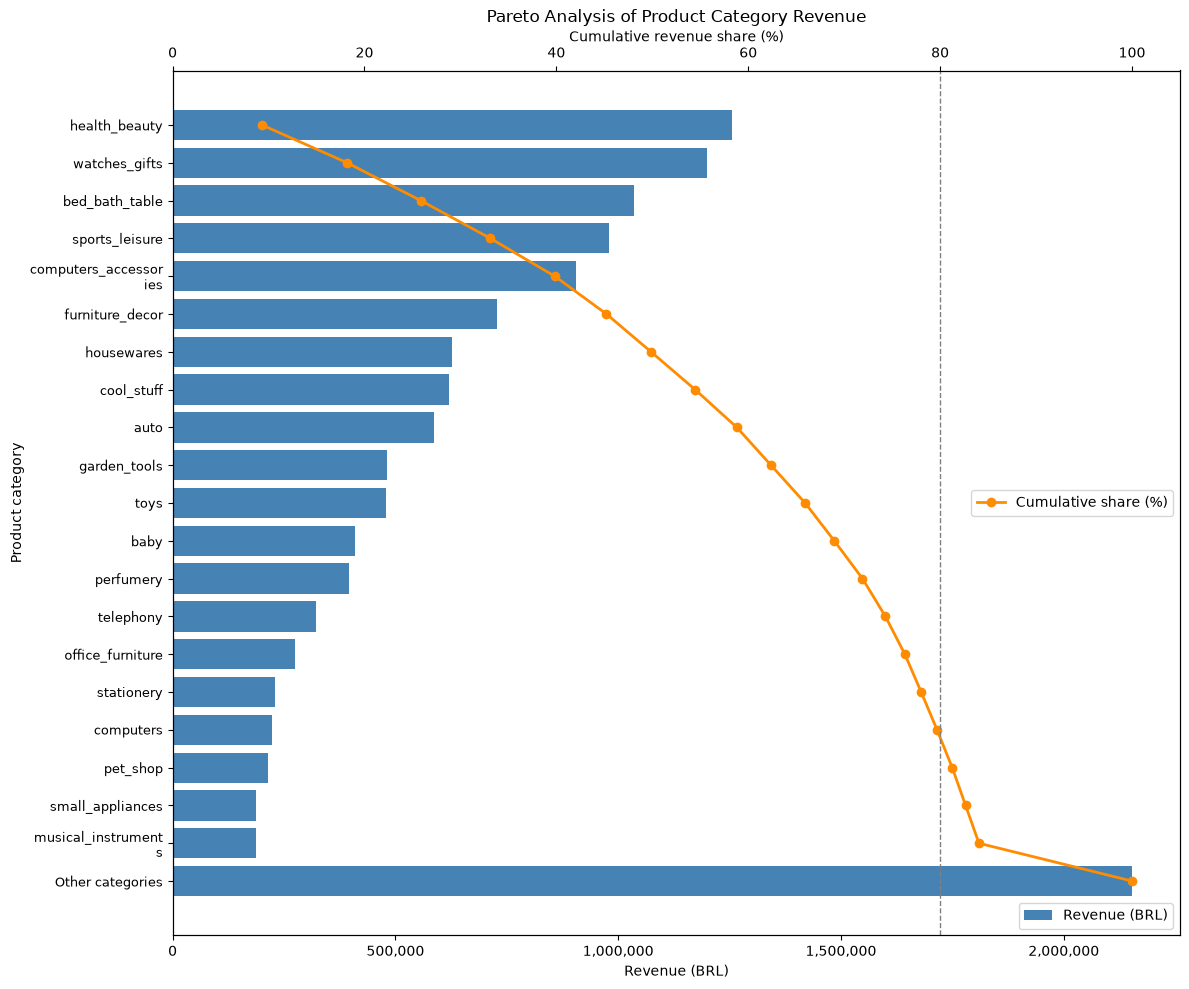

In [32]:
import textwrap

category_col = "product_category_name_english"

pareto = (
    category_analysis[[category_col, "revenue"]]
    .sort_values("revenue", ascending=False)
    .reset_index(drop=True)
)
total_revenue = pareto["revenue"].sum()
top_n = 20  # عدد الفئات المعروضة في الرسمة، والباقي بيتجمع في "Other categories"

# أعلى 20 فئة + تجميع الباقي
top = pareto.head(top_n).copy()
other_revenue = pareto.iloc[top_n:]["revenue"].sum()
if other_revenue > 0:
    other_row = pd.DataFrame({category_col: ["Other categories"], "revenue": [other_revenue]})
    top = pd.concat([top, other_row], ignore_index=True)

top["cumulative_share"] = top["revenue"].cumsum() / total_revenue
top["label"] = top[category_col].astype(str).apply(
    lambda n: "\n".join(textwrap.wrap(n, width=18))
)

# الرسم
fig, ax1 = plt.subplots(figsize=(12, 10))
positions = list(range(len(top)))

ax1.barh(positions, top["revenue"], color="steelblue", label="Revenue (BRL)")
ax1.set_yticks(positions)
ax1.set_yticklabels(top["label"], fontsize=9)
ax1.invert_yaxis()
ax1.set_xlabel("Revenue (BRL)")
ax1.set_ylabel("Product category")
ax1.set_title("Pareto Analysis of Product Category Revenue")
ax1.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))

ax2 = ax1.twiny()
ax2.plot(top["cumulative_share"] * 100, positions, color="darkorange",
         marker="o", linewidth=2, label="Cumulative share (%)")
ax2.set_xlabel("Cumulative revenue share (%)")
ax2.set_xlim(0, 105)
ax2.axvline(80, color="gray", linestyle="--", linewidth=1)

ax1.legend(loc="lower right")
ax2.legend(loc="center right")
plt.tight_layout()
plt.show()

### استنتاج تحليل الفئات (Pareto)

- الإيراد متركز في عدد قليل من الفئات: أعلى 5 فئات (`health_beauty`, `watches_gifts`, `bed_bath_table`, `sports_leisure`, `computers_accessories`) تمثل نحو **40%** من الإيراد، وحوالي **ربع الفئات** فقط يحقق ~80% منه.
- ترتيب الإيراد لا يطابق ترتيب الطلبات. `bed_bath_table` الأولى بالطلبات لكنها الثالثة بالإيراد لأن متوسط سعرها منخفض (~93)، بينما `watches_gifts` الثانية بالإيراد من حوالي 5,600 طلب فقط لأن متوسط سعرها مرتفع (~201).
- فئات مثل `telephony` (متوسط ~71) طلباتها كثيرة وإيرادها محدود، فزيادة عدد الطلبات فيها لا تعني بالضرورة إيرادًا أعلى.
- البنود بدون فئة أو بدون ترجمة (حوالي 1.4% من البنود) محتفظ بيها تحت اسم `unknown` أو اسمها البرتغالي، ولم تُستبعد من الحساب.

## sellers

In [33]:
# جدول sellers
df_seller = pd.read_csv("sellers.csv")

print(df_seller.head())
print(df_seller.shape)
df_seller.info()

                          seller_id  seller_zip_code_prefix  \
0  3442f8959a84dea7ee197c632cb2df15                   13023   
1  d1b65fc7debc3361ea86b5f14c68d2e2                   13844   
2  ce3ad9de960102d0677a81f5d0bb7b2d                   20031   
3  c0f3eea2e14555b6faeea3dd58c1b1c3                    4195   
4  51a04a8a6bdcb23deccc82b0b80742cf                   12914   

         seller_city seller_state  
0           campinas           SP  
1         mogi guacu           SP  
2     rio de janeiro           RJ  
3          sao paulo           SP  
4  braganca paulista           SP  
(3095, 4)
<class 'pandas.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   seller_id               3095 non-null   str  
 1   seller_zip_code_prefix  3095 non-null   int64
 2   seller_city             3095 non-null   str  
 3   seller_state            3095 non-null   

In [34]:
# جدول customers
df_customer = pd.read_csv("customers.csv")

print(df_customer.head())
print(df_customer.shape)
df_customer.info()

                        customer_id                customer_unique_id  \
0  06b8999e2fba1a1fbc88172c00ba8bc7  861eff4711a542e4b93843c6dd7febb0   
1  18955e83d337fd6b2def6b18a428ac77  290c77bc529b7ac935b93aa66c333dc3   
2  4e7b3e00288586ebd08712fdd0374a03  060e732b5b29e8181a18229c7b0b2b5e   
3  b2b6027bc5c5109e529d4dc6358b12c3  259dac757896d24d7702b9acbbff3f3c   
4  4f2d8ab171c80ec8364f7c12e35b23ad  345ecd01c38d18a9036ed96c73b8d066   

   customer_zip_code_prefix          customer_city customer_state  
0                     14409                 franca             SP  
1                      9790  sao bernardo do campo             SP  
2                      1151              sao paulo             SP  
3                      8775        mogi das cruzes             SP  
4                     13056               campinas             SP  
(99441, 5)
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count

In [35]:
# إيراد كل بائع (من بنود الطلبات الصالحة فقط) + بيانات البائع
seller_ord = items_valid.merge(
    df_seller, on="seller_id", how="left", validate="m:1"
)

seller_totals = (
    seller_ord.groupby("seller_id")
    .agg(revenue=("price", "sum"))
    .reset_index()
)

print("sellers:", len(seller_totals))
print(seller_totals.sort_values("revenue", ascending=False).head(10).round(2))

sellers: 3053
                             seller_id    revenue
849   4869f7a5dfa277a7dca6462dcf3b52b2  229237.63
1000  53243585a1d6dc2643021fd1853d8905  222776.05
873   4a3ca9315b744ce9f8e9374361493884  200326.12
2984  fa1c13f2614d7b5c4749cbc52fecda94  192842.13
1515  7c67e1448b00f6e969d365cea6b010ab  187923.89
1540  7e93a43ef30c4f03f38b393420bc753a  172583.88
2611  da8622b14eb17ae2831f4ac5b9dab84a  160236.57
1485  7a67c85e85bb2ce8582c35f2203ad736  141715.54
191   1025f0e2d44d7041d6cf58b6550e0bfa  138968.55
1799  955fee9216a65b617aa5c0531780ce60  135159.70


In [36]:
# حصة أعلى 10% من البائعين في الإيراد
n_top = int(len(seller_totals) * 0.1)
top_sellers = seller_totals.sort_values("revenue", ascending=False).head(n_top)
top_10_per = top_sellers["revenue"].sum() / seller_totals["revenue"].sum() * 100

print(f"top 10% sellers ({n_top} of {len(seller_totals)}) generate {top_10_per:.2f}% of total revenue")

top 10% sellers (305 of 3053) generate 67.43% of total revenue


In [37]:
# توزيع البائعين حسب الولاية (عدد + نسبة)
seller_states = df_seller["seller_state"].value_counts()
seller_states_df = pd.DataFrame({
    "sellers": seller_states,
    "share_%": (seller_states / seller_states.sum() * 100).round(1),
})

print("states:", len(seller_states))
print(seller_states_df.head(10))

states: 23
              sellers  share_%
seller_state                  
SP               1849     59.7
PR                349     11.3
MG                244      7.9
SC                190      6.1
RJ                171      5.5
RS                129      4.2
GO                 40      1.3
DF                 30      1.0
ES                 23      0.7
BA                 19      0.6


In [38]:
# توزيع العملاء حسب الولاية (عملاء فريدين + نسبة)
customers_by_state = (
    df_customer.groupby("customer_state")["customer_unique_id"]
    .nunique()
    .sort_values(ascending=False)
)
customers_by_state_df = pd.DataFrame({
    "customers": customers_by_state,
    "share_%": (customers_by_state / customers_by_state.sum() * 100).round(1),
})

print("states:", len(customers_by_state))
print(customers_by_state_df.head(10))

states: 27
                customers  share_%
customer_state                    
SP                  40302     41.9
RJ                  12384     12.9
MG                  11259     11.7
RS                   5277      5.5
PR                   4882      5.1
SC                   3534      3.7
BA                   3277      3.4
DF                   2075      2.2
ES                   1964      2.0
GO                   1952      2.0


In [39]:
# إيراد كل ولاية بائع (الولاية اللي البيع بيخرج منها، مش ولاية العميل)
state_totals = (
    seller_ord.groupby("seller_state")
    .agg(revenue=("price", "sum"))
    .reset_index()
    .sort_values("revenue", ascending=False)
)
state_totals["share_%"] = (state_totals["revenue"] / state_totals["revenue"].sum() * 100).round(1)

print(state_totals.head(10).round(2))

   seller_state     revenue  share_%
22           SP  8687740.35     64.4
15           PR  1256874.01      9.3
8            MG  1001944.76      7.4
16           RJ   837466.37      6.2
20           SC   624002.96      4.6
19           RS   377726.85      2.8
2            BA   285332.57      2.1
4            DF    97100.48      0.7
13           PE    91463.95      0.7
6            GO    66251.72      0.5


In [40]:
# customer_id بيتولد لكل طلب، والعميل الحقيقي هو customer_unique_id
print("customer_id     :", df_customer["customer_id"].nunique())
print("customer_unique :", df_customer["customer_unique_id"].nunique())

customer_id     : 99441
customer_unique : 96096


In [41]:
# العملاء المتكررين: عميل (customer_unique_id) عنده أكتر من طلب صالح
orders_with_customers = orders_valid.merge(
    df_customer[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left",
    validate="m:1",
)

orders_per_customer = orders_with_customers.groupby("customer_unique_id")["order_id"].nunique()

repeat_customers = (orders_per_customer > 1).sum()
repeat_rate = repeat_customers / len(orders_per_customer) * 100

print("Unique customers:", len(orders_per_customer))
print("Customers with repeat purchases:", repeat_customers)
print(f"Repeat-purchase rate: {repeat_rate:.2f}%")

Unique customers: 94990
Customers with repeat purchases: 2888
Repeat-purchase rate: 3.04%


In [42]:
# جدول payments
payment = pd.read_csv("order_payments.csv")

print(payment.head())
print(payment.shape)
payment.info()

                           order_id  payment_sequential payment_type  \
0  b81ef226f3fe1789b1e8b2acac839d17                   1  credit_card   
1  a9810da82917af2d9aefd1278f1dcfa0                   1  credit_card   
2  25e8ea4e93396b6fa0d3dd708e76c1bd                   1  credit_card   
3  ba78997921bbcdc1373bb41e913ab953                   1  credit_card   
4  42fdf880ba16b47b59251dd489d4441a                   1  credit_card   

   payment_installments  payment_value  
0                     8          99.33  
1                     1          24.39  
2                     1          65.71  
3                     8         107.78  
4                     2         128.45  
(103886, 5)
<class 'pandas.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  str    
 1   payment_sequential    103886 non-null  int64  
 2

In [ ]:
# عدد عمليات الدفع حسب النوع
payment_counts = payment["payment_type"].value_counts()
print(pd.DataFrame({
    "payments": payment_counts,
    "share_%": (payment_counts / payment_counts.sum() * 100).round(1),
}))

              payments  share_%
payment_type                   
credit_card      76795     73.9
boleto           19784     19.0
voucher           5775      5.6
debit_card        1529      1.5
not_defined          3      0.0


In [64]:
# إجمالي قيمة الدفع حسب النوع
payment_type_value = (
    payment.groupby("payment_type")
    .agg(payment_type_value=("payment_value", "sum"))
    .sort_values("payment_type_value", ascending=False)
)
payment_type_value["share_%"] = (
    payment_type_value["payment_type_value"] / payment_type_value["payment_type_value"].sum() * 100
).round(1)

print(payment_type_value.round(2))

              payment_type_value  share_%
payment_type                             
credit_card          12542084.19     78.3
boleto                2869361.27     17.9
voucher                379436.87      2.4
debit_card             217989.79      1.4
not_defined                 0.00      0.0


In [65]:
# عدد الأقساط (installments) مرتبة بعدد الأقساط
installments = payment["payment_installments"].value_counts().sort_index()
print(installments)
print(f"\nSingle payment (1 installment): {installments.loc[1] / installments.sum() * 100:.1f}%")

payment_installments
0         2
1     52546
2     12413
3     10461
4      7098
5      5239
6      3920
7      1626
8      4268
9       644
10     5328
11       23
12      133
13       16
14       15
15       74
16        5
17        8
18       27
20       17
21        3
22        1
23        1
24       18
Name: count, dtype: int64

Single payment (1 installment): 50.6%


In [66]:
# مجموع الدفع لكل طلب (الطلب ممكن يدفع بأكتر من عملية)
unique_order_paymens = payment.groupby("order_id").agg(
    each_order_value=("payment_value", "sum")
).reset_index()

print("payment rows:", len(payment))
print("unique orders in payments:", unique_order_paymens["order_id"].nunique())
print("orders without payment:", df_orders["order_id"].nunique() - unique_order_paymens["order_id"].nunique())

unique_order_paymens.head()

payment rows: 103886
unique orders in payments: 99440
orders without payment: 1


,order_id,each_order_value
0,00010242fe8c5a6d1ba2dd792cb16214,72.19
1,00018f77f2f0320c557190d7a144bdd3,259.83
2,000229ec398224ef6ca0657da4fc703e,216.87
3,00024acbcdf0a6daa1e931b038114c75,25.78
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04


In [48]:
df_order_item.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [ ]:
# مجموع السعر والشحن لكل طلب من order_items
order_price_freight = df_order_item.groupby("order_id").agg(
    each_order_price=("price", "sum"),
    each_order_freight=("freight_value", "sum"),
).reset_index()

print("item rows:", len(df_order_item))
print("unique orders:", order_price_freight["order_id"].nunique())

item rows: 112650
unique orders: 98666


In [ ]:
order_total = order_price_freight.merge(
    unique_order_paymens, on="order_id", how="inner", validate="1:1"
)
print("orders in both tables:", len(order_total))
print("orders with items but no payment:", len(order_price_freight) - len(order_total))

orders in both tables: 98665
orders with items but no payment: 1


In [70]:
# المتوقع = السعر + الشحن، والفرق = الدفع الفعلي - المتوقع
order_total["expected_total"] = order_total["each_order_price"] + order_total["each_order_freight"]
order_total["payment_diff"] = (order_total["each_order_value"] - order_total["expected_total"]).round(2)

print(order_total["payment_diff"].describe().round(2))

count    98665.00
mean         0.03
std          1.13
min        -51.62
25%          0.00
50%          0.00
75%          0.00
max        182.81
Name: payment_diff, dtype: float64


In [71]:
# مطابقة الدفع: أي فرق أكبر من 0.01 يعتبر فرق حقيقي (مش تقريب)
tolerance = 0.01

different_orders = order_total["payment_diff"].abs() > tolerance
different_count = different_orders.sum()
total_orders = len(order_total)
difference_rate = different_count / total_orders * 100

print("Total orders:", total_orders)
print("Orders with differences:", different_count)
print(f"Difference rate: {difference_rate:.2f}%")
print(f"Of these, payment > expected: {(order_total.loc[different_orders, 'payment_diff'] > 0).mean() * 100:.1f}%")

Total orders: 98665
Orders with differences: 303
Difference rate: 0.31%
Of these, payment > expected: 87.1%


In [72]:
# جدول reviews
reviews = pd.read_csv("order_reviews.csv")

print(reviews.head())
print(reviews.shape)
reviews.info()

                          review_id                          order_id  \
0  7bc2406110b926393aa56f80a40eba40  73fc7af87114b39712e6da79b0a377eb   
1  80e641a11e56f04c1ad469d5645fdfde  a548910a1c6147796b98fdf73dbeba33   
2  228ce5500dc1d8e020d8d1322874b6f0  f9e4b658b201a9f2ecdecbb34bed034b   
3  e64fb393e7b32834bb789ff8bb30750e  658677c97b385a9be170737859d3511b   
4  f7c4243c7fe1938f181bec41a392bdeb  8e6bfb81e283fa7e4f11123a3fb894f1   

   review_score review_comment_title  \
0             4                  NaN   
1             5                  NaN   
2             5                  NaN   
3             5                  NaN   
4             5                  NaN   

                              review_comment_message review_creation_date  \
0                                                NaN  2018-01-18 00:00:00   
1                                                NaN  2018-03-10 00:00:00   
2                                                NaN  2018-02-17 00:00:00   
3           

In [73]:
# توزيع تقييمات العملاء (review_score)
score_counts = reviews["review_score"].value_counts().sort_index()
print(pd.DataFrame({
    "reviews": score_counts,
    "share_%": (score_counts / score_counts.sum() * 100).round(1),
}))

              reviews  share_%
review_score                  
1               11424     11.5
2                3151      3.2
3                8179      8.2
4               19142     19.3
5               57328     57.8


In [74]:
# بعض الطلبات ليها أكتر من تقييم، فبنختار تقييم واحد لكل طلب (الأحدث) في الخلية اللي بعدها
review_counts = reviews.groupby("order_id").size()

print("Orders with reviews:", len(review_counts))
print("Orders with multiple reviews:", (review_counts > 1).sum())
print("Maximum reviews per order:", review_counts.max())

Orders with reviews: 98673
Orders with multiple reviews: 547
Maximum reviews per order: 3


delivered: 96470 | reviews: 98673 | after merge: 95824
             orders  avg_score  low_pct
late_orders                            
On time       88163       4.29      9.2
Late           7661       2.57     54.1


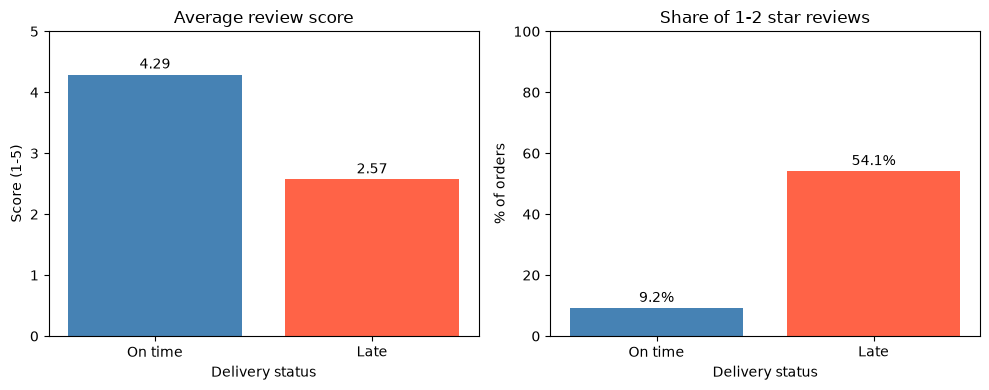

In [75]:
# 1. آخر تقييم لكل طلب (عشان الطلب ما يتعدش أكتر من مرة)
reviews_last = (
    reviews.sort_values("review_answer_timestamp")
    .drop_duplicates("order_id", keep="last")
)

dr = delivered[["order_id", "late_orders"]].merge(
    reviews_last[["order_id", "review_score"]],
    on="order_id", how="inner", validate="one_to_one"
)
print("delivered:", len(delivered), "| reviews:", len(reviews_last), "| after merge:", len(dr))

# 2. عمود True/False للتقييم المنخفض (1-2 نجمة)
dr["is_low"] = dr["review_score"] <= 2

# 3. المقارنة: متأخر مقابل في الميعاد
summary = dr.groupby("late_orders").agg(
    orders=("order_id", "count"),
    avg_score=("review_score", "mean"),
    low_pct=("is_low", "mean"),
)
summary["avg_score"] = summary["avg_score"].round(2)
summary["low_pct"] = (summary["low_pct"] * 100).round(1)
summary.index = summary.index.map({False: "On time", True: "Late"})
print(summary)

# 4. الرسمة
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
colors = ["steelblue", "tomato"]

bars1 = axes[0].bar(summary.index, summary["avg_score"], color=colors)
axes[0].bar_label(bars1, fmt="%.2f", padding=2)
axes[0].set_title("Average review score")
axes[0].set_ylabel("Score (1-5)")
axes[0].set_ylim(0, 5)

bars2 = axes[1].bar(summary.index, summary["low_pct"], color=colors)
axes[1].bar_label(bars2, fmt="%.1f%%", padding=2)
axes[1].set_title("Share of 1-2 star reviews")
axes[1].set_ylabel("% of orders")
axes[1].set_ylim(0, 100)

for ax in axes:
    ax.set_xlabel("Delivery status")

plt.tight_layout()
plt.show()

### التأخير والتقييم

التأخير في التسليم مرتبط بانخفاض متوسط التقييم بمقدار **~1.72 نجمة** (من **4.29** للطلبات في الميعاد إلى **2.57** للمتأخرة). كما أن **54.1%** من الطلبات المتأخرة حصلت على تقييم 1–2 نجمة، مقابل **9.2%** للطلبات في الميعاد. هذا ارتباط قوي وليس إثباتًا للسببية.

In [78]:
# تقييم الفئات: نسبة التقييمات المنخفضة (1-2 نجمة) لكل فئة
x = (
    items_cat.loc[
        items_cat["product_category_name_english"] != "unknown",
        ["order_id", "product_category_name_english"],
    ]
    .drop_duplicates()
)

# 2. ضم آخر تقييم لكل طلب 
rc = x.merge(
    reviews_last[["order_id", "review_score"]],
    on="order_id", how="inner", validate="many_to_one"
)

rc["is_low"] = rc["review_score"] <= 2

# 3. لكل فئة: عدد الطلبات + نسبة التقييم المنخفض
cat = rc.groupby("product_category_name_english").agg(
    orders=("order_id", "count"),
    low_pct=("is_low", "mean"),
)
cat["low_pct"] = (cat["low_pct"] * 100).round(1)

cat = cat[cat["orders"] >= 500]
print(f"Overall low-review rate: {rc['is_low'].mean() * 100:.1f}%")
print(cat.sort_values("low_pct", ascending=False).head(5))

Overall low-review rate: 14.4%
                               orders  low_pct
product_category_name_english                 
office_furniture                 1263     22.6
bed_bath_table                   9313     16.8
furniture_decor                  6398     16.7
computers_accessories            6649     16.1
baby                             2861     16.0


### الفئات الأكثر تسجيلاً لتقييمات منخفضة

بين الفئات التي لديها 500 طلب على الأقل، كانت أعلى نسبة تقييم منخفض (1–2 نجمة) في `office_furniture` بنسبة **22.6%**، تليها `bed_bath_table` (**16.8%**) و`furniture_decor` (**16.7%**) و`computers_accessories` (**16.1%**) و`baby` (**16.0%**)، مقارنة بمتوسط عام يقارب **15%**. تتكرر فئات الأثاث والمفروشات في القائمة، مما يستدعي مراجعة جودة المنتجات والموردين فيها.